# Probabilistic Matrix Factorization with Alternating Least Squares (ALS)
### Practicals 1 to 5 on the MovieLens-32M Dataset

We import the required libraries and set the dataset paths and random seed.

In [1]:
import os
import csv
import time
import array as arr
import pickle as pkl
from typing import Dict, Any, Tuple, List

import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

DATASET_CSV_PATH = "ratings.csv"
MOVIES_CSV_PATH = "movies.csv"
DATASET_PATH = "dataset.pkl"
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"Configuration set. Target dataset: {DATASET_PATH}")

Configuration set. Target dataset: dataset.pkl


---
# Practical 1: Data Parsing and Exploration

### 1.1 Dual-Indexed Data Structure (by User and by Movie)
We define `parsefile` to parse `ratings.csv` into a dual Compressed Sparse Row (CSR) data structure indexed both by user (`users_offsets`, `users_movies`, `users_ratings`) and by movie (`movies_offsets`, `movies_users`, `movies_ratings`).

In [2]:
def parsefile(filename: str, label_func=lambda u, m, t: 1 if np.random.random() < 0.8 else 0) -> Dict[str, Any]:
    """Parses MovieLens CSV into a dual CSR data structure indexed by user and by movie."""
    user_index = {}
    movie_index = {}

    user_ids_mapped = arr.array("I")
    movie_ids_mapped = arr.array("I")
    ratings_mapped = arr.array("B")  # Half-star units (1..10)
    labels = arr.array("B")

    user_counts = []
    movie_counts = []

    with open(filename, "r", encoding="utf-8", buffering=4 * 1024 * 1024) as f:
        f.readline()  # Skip header
        for line in f:
            row = line.rstrip().split(",")
            if len(row) < 3:
                continue
            u_str, m_str, r_str, tmstp = row[0], row[1], row[2], row[3]

            u_id = user_index.get(u_str)
            if u_id is None:
                u_id = len(user_index)
                user_index[u_str] = u_id
                user_counts.append(0)

            m_id = movie_index.get(m_str)
            if m_id is None:
                m_id = len(movie_index)
                movie_index[m_str] = m_id
                movie_counts.append(0)

            user_ids_mapped.append(u_id)
            movie_ids_mapped.append(m_id)
            ratings_mapped.append(int(2 * float(r_str)))
            labels.append(label_func(u_id, m_id, tmstp))

            user_counts[u_id] += 1
            movie_counts[m_id] += 1

    num_users = len(user_index)
    num_movies = len(movie_index)
    num_ratings = len(ratings_mapped)

    users_offsets = arr.array("I", [0] * (num_users + 1))
    movies_offsets = arr.array("I", [0] * (num_movies + 1))

    acc = 0
    for i in range(num_users):
        acc += user_counts[i]
        users_offsets[i + 1] = acc

    acc = 0
    for i in range(num_movies):
        acc += movie_counts[i]
        movies_offsets[i + 1] = acc

    users_movies = arr.array("I", [0] * num_ratings)
    users_ratings = arr.array("B", [0] * num_ratings)
    users_labels = arr.array("B", [0] * num_ratings)

    movies_users = arr.array("I", [0] * num_ratings)
    movies_ratings = arr.array("B", [0] * num_ratings)
    movies_labels = arr.array("B", [0] * num_ratings)

    user_positions = list(users_offsets[:-1])
    movie_positions = list(movies_offsets[:-1])

    for i in range(num_ratings):
        u = user_ids_mapped[i]
        m = movie_ids_mapped[i]
        r = ratings_mapped[i]
        l = labels[i]

        u_pos = user_positions[u]
        users_movies[u_pos] = m
        users_ratings[u_pos] = r
        users_labels[u_pos] = l
        user_positions[u] += 1

        m_pos = movie_positions[m]
        movies_users[m_pos] = u
        movies_ratings[m_pos] = r
        movies_labels[m_pos] = l
        movie_positions[m] += 1

    user_index_rev = [None] * num_users
    for k, v in user_index.items():
        user_index_rev[v] = k

    movie_index_rev = [None] * num_movies
    for k, v in movie_index.items():
        movie_index_rev[v] = k

    return {
        "users_index": user_index, "users_index_rev": user_index_rev,
        "users_ratings": users_ratings, "users_offsets": users_offsets,
        "users_movies": users_movies, "users_labels": users_labels,
        "movies_index": movie_index, "movies_index_rev": movie_index_rev,
        "movies_ratings": movies_ratings, "movies_offsets": movies_offsets,
        "movies_users": movies_users, "movies_labels": movies_labels,
    }


def load_dataset(filename: str) -> Dict[str, Any]:
    with open(filename, "rb") as f:
        return pkl.load(f)

We parse `ratings.csv` (or load `dataset.pkl` if already parsed) and inspect the summary statistics.

In [3]:
t0 = time.perf_counter()
if not os.path.exists(DATASET_PATH):
    print("Parsing CSV file...")
    dataset = parsefile(DATASET_CSV_PATH)
    with open(DATASET_PATH, "wb") as f:
        pkl.dump(dataset, f)
    print(f"Parsed and saved to {DATASET_PATH} in {time.perf_counter() - t0:.2f}s.")
else:
    print(f"Loading {DATASET_PATH}...")
    dataset = load_dataset(DATASET_PATH)
    print(f"Loaded in {time.perf_counter() - t0:.2f}s.")

n_users = len(dataset["users_index"])
n_movies = len(dataset["movies_index"])
n_ratings = len(dataset["users_ratings"])

print(f"Unique Users:  {n_users:,}")
print(f"Unique Movies: {n_movies:,}")
print(f"Total Ratings: {n_ratings:,}")

Loading dataset.pkl...
Loaded in 2.92s.
Unique Users:  200,948
Unique Movies: 84,432
Total Ratings: 32,000,204


### 1.2 Rating Distribution
We compute the frequency of each star rating value ($0.5$ to $5.0$) and plot the empirical rating distribution.

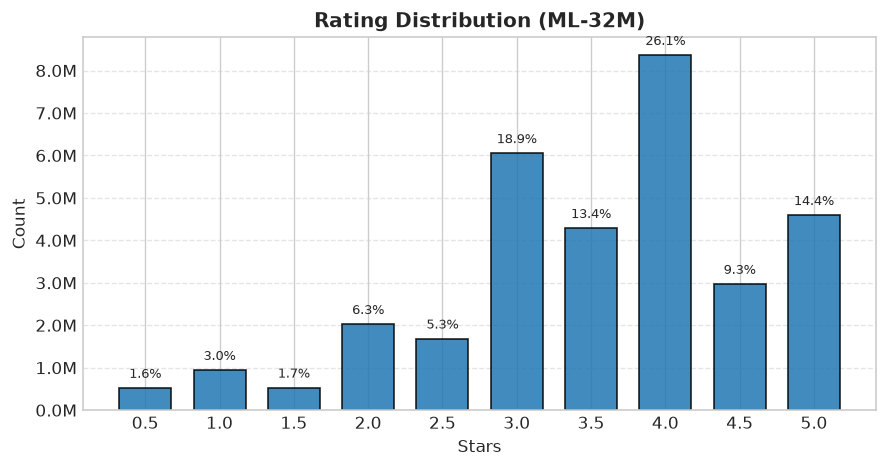

In [4]:
ratings_raw = np.array(dataset["users_ratings"], dtype=np.uint8) / 2.0
unique_ratings, rating_counts = np.unique(ratings_raw, return_counts=True)

plt.figure(figsize=(7.5, 4.0))
bars = plt.bar(unique_ratings, rating_counts, width=0.35, color="#1f77b4", edgecolor="black", alpha=0.85)
plt.title("Rating Distribution (ML-32M)", fontsize=12, fontweight="bold")
plt.xlabel("Stars", fontsize=10)
plt.ylabel("Count", fontsize=10)
plt.xticks(unique_ratings)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x*1e-6:.1f}M'))
plt.grid(axis='y', linestyle='--', alpha=0.5)

total_r = len(ratings_raw)
for bar in bars:
    h = bar.get_height()
    pct = (h / total_r) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, h + total_r * 0.005, f"{pct:.1f}%", ha='center', va='bottom', fontsize=8.0)

plt.tight_layout()
plt.show()

### 1.3 User and Movie Degree Distributions (Log-Log Scale)
We compute the number of ratings per user (out-degree) and per movie (in-degree) from the CSR offset arrays and plot their frequency distributions on a log-log scale.

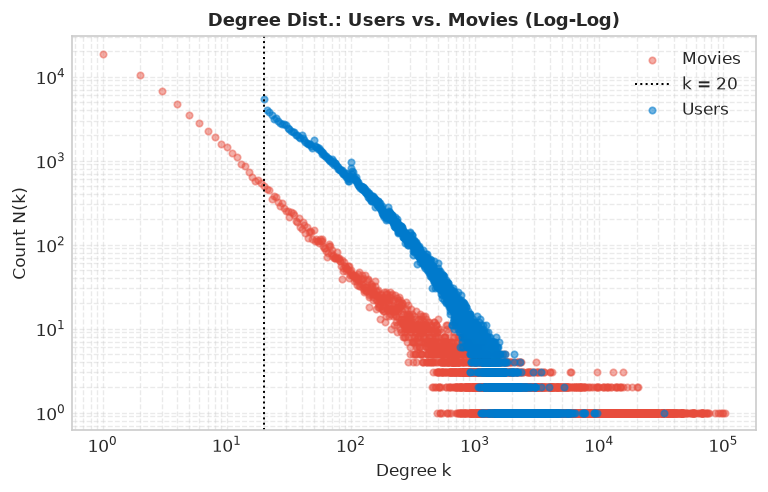

In [5]:
users_offsets = np.array(dataset["users_offsets"], dtype=np.int64)
movies_offsets = np.array(dataset["movies_offsets"], dtype=np.int64)

movies_per_user = np.diff(users_offsets)
users_per_movie = np.diff(movies_offsets)

u_deg, u_counts = np.unique(movies_per_user, return_counts=True)
m_deg, m_counts = np.unique(users_per_movie, return_counts=True)

fig, ax = plt.subplots(figsize=(6.5, 4.2))

ax.scatter(m_deg, m_counts, color="#e74c3c", alpha=0.45, s=15, label="Movies")
ax.axvline(x=20, color="black", linestyle=":", linewidth=1.2, label="k = 20")
ax.scatter(u_deg, u_counts, color="#007acc", alpha=0.55, s=15, label="Users")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Degree Dist.: Users vs. Movies (Log-Log)", fontsize=11, fontweight="bold")
ax.set_xlabel("Degree k")
ax.set_ylabel("Count N(k)")
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

---
# Practical 2: Bias-Only Model (ALS)

### 2.1 Train/Test Split and CSR Indexing
We split the dataset into training ($80\%$) and test ($20\%$) sets and build both user-indexed and movie-indexed CSR views with ratings converted to star units ($0.5..5.0$).

In [6]:
def get_train_test_split(dataset: Dict[str, Any]) -> Tuple[Dict[str, Any], Dict[str, Any]]:
    """Splits the dual-indexed dataset into user-centric and movie-centric train/test CSR views."""
    train_data = {}
    test_data = {}

    n_u = len(dataset["users_offsets"]) - 1
    n_m = len(dataset["movies_offsets"]) - 1

    # Movie-centric view
    m_ratings = np.array(dataset["movies_ratings"], dtype=np.float64) / 2.0
    m_offsets = np.array(dataset["movies_offsets"], dtype=np.int64)
    m_counts_all = np.diff(m_offsets)
    movies_ids = np.repeat(np.arange(n_m, dtype=np.int32), m_counts_all)
    m_mask = np.array(dataset["movies_labels"], dtype=np.uint8) > 0

    train_data["movies_ratings"] = np.ascontiguousarray(m_ratings[m_mask])
    test_data["movies_ratings"] = np.ascontiguousarray(m_ratings[~m_mask])
    train_data["movies_ids"] = np.ascontiguousarray(movies_ids[m_mask])
    test_data["movies_ids"] = np.ascontiguousarray(movies_ids[~m_mask])
    train_data["movies_users"] = np.ascontiguousarray(np.array(dataset["movies_users"], dtype=np.int32)[m_mask])
    test_data["movies_users"] = np.ascontiguousarray(np.array(dataset["movies_users"], dtype=np.int32)[~m_mask])

    train_m_counts = np.bincount(train_data["movies_ids"], minlength=n_m)
    train_data["movies_offsets"] = np.zeros(n_m + 1, dtype=np.int64)
    train_data["movies_offsets"][1:] = np.cumsum(train_m_counts)

    # User-centric view
    u_ratings = np.array(dataset["users_ratings"], dtype=np.float64) / 2.0
    u_offsets = np.array(dataset["users_offsets"], dtype=np.int64)
    u_counts_all = np.diff(u_offsets)
    users_ids = np.repeat(np.arange(n_u, dtype=np.int32), u_counts_all)
    u_mask = np.array(dataset["users_labels"], dtype=np.uint8) > 0

    train_data["users_ratings"] = np.ascontiguousarray(u_ratings[u_mask])
    test_data["users_ratings"] = np.ascontiguousarray(u_ratings[~u_mask])
    train_data["users_ids"] = np.ascontiguousarray(users_ids[u_mask])
    test_data["users_ids"] = np.ascontiguousarray(users_ids[~u_mask])
    train_data["users_movies"] = np.ascontiguousarray(np.array(dataset["users_movies"], dtype=np.int32)[u_mask])
    test_data["users_movies"] = np.ascontiguousarray(np.array(dataset["users_movies"], dtype=np.int32)[~u_mask])

    train_u_counts = np.bincount(train_data["users_ids"], minlength=n_u)
    train_data["users_offsets"] = np.zeros(n_u + 1, dtype=np.int64)
    train_data["users_offsets"][1:] = np.cumsum(train_u_counts)

    return train_data, test_data


t0 = time.perf_counter()
train_data, test_data = get_train_test_split(dataset)
print(f"Split finished in {time.perf_counter() - t0:.2f}s | Train: {len(train_data['users_ratings']):,} | Test: {len(test_data['users_ratings']):,}")

Split finished in 3.20s | Train: 25,604,307 | Test: 6,395,897


### 2.2 Bias-Only ALS Update Functions
We implement the closed-form alternating least squares updates for user biases $a_u$ and movie biases $b_i$, along with the loss and RMSE evaluation functions.

In [7]:
def init_bias_params(n_users: int, n_movies: int) -> Tuple[np.ndarray, np.ndarray]:
    return np.zeros(n_users, dtype=np.float64), np.zeros(n_movies, dtype=np.float64)


def update_entities_bias(own_bias: np.ndarray, other_bias: np.ndarray,
                         ratings: np.ndarray, other_ids: np.ndarray,
                         unique_ids: np.ndarray, inv_idx: np.ndarray, counts: np.ndarray,
                         lambdda: float, gamma: float, mu: float) -> None:
    residues = ratings - other_bias[other_ids] - mu
    summed_residues = np.bincount(inv_idx, weights=residues) * lambdda
    own_bias[unique_ids] = summed_residues / (lambdda * counts + gamma)


def compute_bias_metrics(users_bias: np.ndarray, movies_bias: np.ndarray,
                         mu: float, lambdda: float, gamma: float,
                         dataset_view: Dict[str, Any], by_movie: bool = False) -> Tuple[float, float, float]:
    if not by_movie:
        ratings = dataset_view["users_ratings"]
        u_idx = dataset_view["users_ids"]
        m_idx = dataset_view["users_movies"]
    else:
        ratings = dataset_view["movies_ratings"]
        u_idx = dataset_view["movies_users"]
        m_idx = dataset_view["movies_ids"]

    err = ratings - (mu + users_bias[u_idx] + movies_bias[m_idx])
    sse = float(np.sum(err ** 2))
    nll = 0.5 * lambdda * sse
    reg = 0.5 * gamma * float(np.sum(users_bias ** 2) + np.sum(movies_bias ** 2))
    rmse = float(np.sqrt(sse / len(ratings)))
    return nll, nll + reg, rmse

### 2.3 Training the Bias-Only Model
We run the bias-only ALS algorithm for $10$ iterations and check that the loss computed from `data_by_user_train` and `data_by_movie_train` is identical.

In [8]:
u_ids, u_inv_idx, u_counts = np.unique(train_data["users_ids"], return_inverse=True, return_counts=True)
m_ids, m_inv_idx, m_counts = np.unique(train_data["movies_ids"], return_inverse=True, return_counts=True)

lambdda_b = 1.0
gamma_b = 5.0
mu = float(np.mean(train_data["users_ratings"]))
n_iters_b = 10

users_bias_p2, movies_bias_p2 = init_bias_params(n_users, n_movies)

p2_nll_user, p2_loss_user, p2_tr_rmse, p2_te_rmse = [], [], [], []
p2_loss_movie = []

nll_u, loss_u, tr_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=False)
_, loss_m, _ = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=True)
_, _, te_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, test_data, by_movie=False)

p2_nll_user.append(nll_u)
p2_loss_user.append(loss_u)
p2_loss_movie.append(loss_m)
p2_tr_rmse.append(tr_r)
p2_te_rmse.append(te_r)

print(f"Iter  0 | Loss (User): {loss_u:13,.2f} | Loss (Movie): {loss_m:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f}")
t0 = time.perf_counter()
for it in range(1, n_iters_b + 1):
    update_entities_bias(users_bias_p2, movies_bias_p2,
                         train_data["users_ratings"], train_data["users_movies"],
                         u_ids, u_inv_idx, u_counts, lambdda_b, gamma_b, mu)
    update_entities_bias(movies_bias_p2, users_bias_p2,
                         train_data["movies_ratings"], train_data["movies_users"],
                         m_ids, m_inv_idx, m_counts, lambdda_b, gamma_b, mu)

    nll_u, loss_u, tr_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=False)
    _, loss_m, _ = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, train_data, by_movie=True)
    _, _, te_r = compute_bias_metrics(users_bias_p2, movies_bias_p2, mu, lambdda_b, gamma_b, test_data, by_movie=False)

    p2_nll_user.append(nll_u)
    p2_loss_user.append(loss_u)
    p2_loss_movie.append(loss_m)
    p2_tr_rmse.append(tr_r)
    p2_te_rmse.append(te_r)
    print(f"Iter {it:2d} | Loss (User): {loss_u:13,.2f} | Loss (Movie): {loss_m:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f}")

print(f"Completed in {time.perf_counter() - t0:.2f}s | Max |Loss_user - Loss_movie| = { max(abs(a - b) for a, b in zip(p2_loss_user, p2_loss_movie)):.2e}")

Iter  0 | Loss (User): 14,354,702.85 | Loss (Movie): 14,354,702.85 | Train RMSE: 1.0589 | Test RMSE: 1.0593
Iter  1 | Loss (User):  9,619,726.85 | Loss (Movie):  9,619,726.85 | Train RMSE: 0.8611 | Test RMSE: 0.8698
Iter  2 | Loss (User):  9,313,317.90 | Loss (Movie):  9,313,317.90 | Train RMSE: 0.8477 | Test RMSE: 0.8564
Iter  3 | Loss (User):  9,299,242.94 | Loss (Movie):  9,299,242.94 | Train RMSE: 0.8471 | Test RMSE: 0.8557
Iter  4 | Loss (User):  9,297,698.73 | Loss (Movie):  9,297,698.73 | Train RMSE: 0.8470 | Test RMSE: 0.8557
Iter  5 | Loss (User):  9,296,940.31 | Loss (Movie):  9,296,940.31 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  6 | Loss (User):  9,296,308.16 | Loss (Movie):  9,296,308.16 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  7 | Loss (User):  9,295,738.95 | Loss (Movie):  9,295,738.95 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  8 | Loss (User):  9,295,219.64 | Loss (Movie):  9,295,219.64 | Train RMSE: 0.8470 | Test RMSE: 0.8556
Iter  9 | Loss (User):  9,29

### 2.4 Plotting Bias-Only Loss and RMSE Curves
We plot the regularized loss (by user and by movie) and the training and test RMSE across ALS iterations.

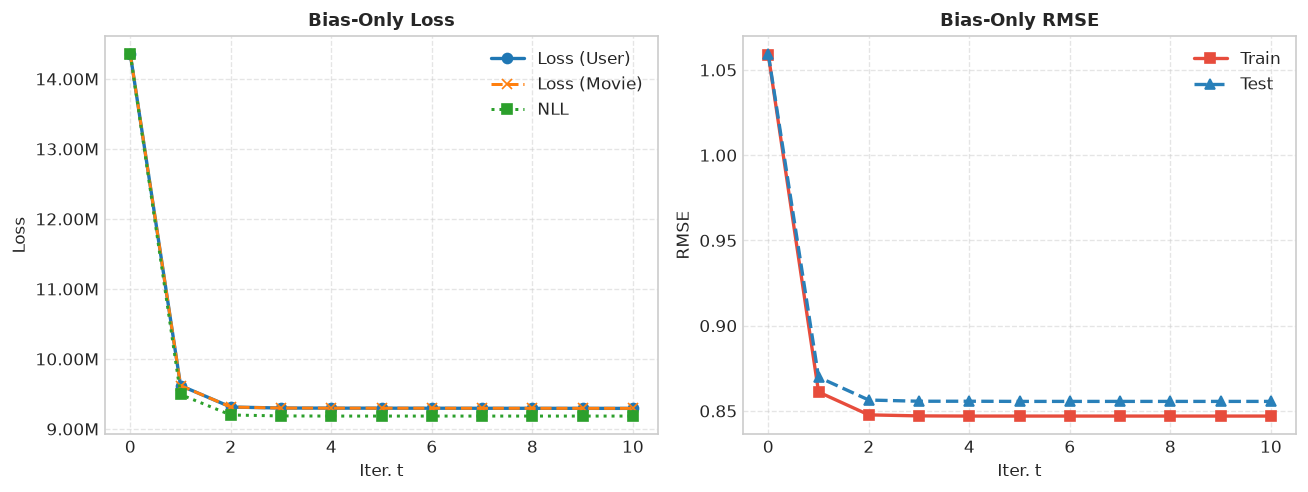

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
iters_b = np.arange(len(p2_loss_user))

axes[0].plot(iters_b, p2_loss_user, marker='o', linewidth=2, color="#1f77b4", label="Loss (User)")
axes[0].plot(iters_b, p2_loss_movie, marker='x', linestyle="--", linewidth=1.8, color="#ff7f0e", label="Loss (Movie)")
axes[0].plot(iters_b, p2_nll_user, marker='s', linestyle=":", linewidth=1.8, color="#2ca02c", label="NLL")
axes[0].set_title("Bias-Only Loss", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Iter. t")
axes[0].set_ylabel("Loss")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x*1e-6:.2f}M'))
axes[0].legend(frameon=False)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(iters_b, p2_tr_rmse, marker='s', linewidth=2, color="#e74c3c", label="Train")
axes[1].plot(iters_b, p2_te_rmse, marker='^', linestyle="--", linewidth=2, color="#2980b9", label="Test")
axes[1].set_title("Bias-Only RMSE", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Iter. t")
axes[1].set_ylabel("RMSE")
axes[1].legend(frameon=False)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
# Practical 3: Matrix Factorization Model (ALS)

### 3.1 Batched NumPy Matrix Factorization Implementation
We implement the matrix factorization ALS updates for user biases $a_u$, user trait vectors $u_u \in \mathbb{R}^K$, movie biases $b_i$, and movie trait vectors $v_i \in \mathbb{R}^K$ using chunked NumPy `reduceat` outer-product accumulation and `np.linalg.solve`.

In [10]:
def init_pmf_params(n_users: int, n_movies: int, emb_dim: int = 10,
                    tau: float = 5.0, seed: int = 42) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    scale = 1.0 / np.sqrt(emb_dim * max(tau, 1.0))
    users_bias = np.zeros(n_users, dtype=np.float64)
    movies_bias = np.zeros(n_movies, dtype=np.float64)
    users_emb = rng.normal(0.0, scale, size=(n_users, emb_dim)).astype(np.float64)
    movies_emb = rng.normal(0.0, scale, size=(n_movies, emb_dim)).astype(np.float64)
    return users_emb, users_bias, movies_emb, movies_bias


def get_breakpoints(offsets: np.ndarray, chunk_size: int = 800_000) -> List[int]:
    breakpoints = [0]
    counts = np.diff(offsets)
    size = 0
    for i, count in enumerate(counts):
        if size + count > chunk_size and size > 0:
            breakpoints.append(int(offsets[i]))
            size = 0
        size += int(count)
    breakpoints.append(int(offsets[-1]))
    return breakpoints


def update_users_bias_pmf(users_emb: np.ndarray, users_bias: np.ndarray,
                          movies_emb: np.ndarray, movies_bias: np.ndarray,
                          lambdda: float, gamma: float, mu: float,
                          train_data: Dict[str, Any],
                          unique_u_ids: np.ndarray, u_inv_idx: np.ndarray, u_counts: np.ndarray,
                          chunk_size: int = 2_000_000):
    ratings = train_data["users_ratings"]
    users_ids = train_data["users_ids"]
    movies_ids = train_data["users_movies"]
    n = len(ratings)
    residues = np.empty(n, dtype=np.float64)
    for start in range(0, n, chunk_size):
        end = min(start + chunk_size, n)
        dots = np.sum(users_emb[users_ids[start:end]] * movies_emb[movies_ids[start:end]], axis=1)
        residues[start:end] = ratings[start:end] - movies_bias[movies_ids[start:end]] - mu - dots
    summed = np.bincount(u_inv_idx, weights=residues) * lambdda
    users_bias[unique_u_ids] = summed / (lambdda * u_counts + gamma)


def update_users_emb_pmf(users_emb: np.ndarray, users_bias: np.ndarray,
                         movies_emb: np.ndarray, movies_bias: np.ndarray,
                         lambdda: float, tau: float, mu: float,
                         train_data: Dict[str, Any], breakpoints: List[int]):
    ratings = train_data["users_ratings"]
    users_ids = train_data["users_ids"]
    movies_ids = train_data["users_movies"]
    k = users_emb.shape[1]
    eye_k = tau * np.eye(k, dtype=np.float64)[None, :, :]

    for i in range(len(breakpoints) - 1):
        start, end = breakpoints[i], breakpoints[i + 1]
        if start >= end:
            continue
        u_slice = users_ids[start:end]
        m_slice = movies_ids[start:end]
        mask = u_slice[:-1] != u_slice[1:]
        cut_points = np.concatenate(([0], np.nonzero(mask)[0] + 1))
        u_chunk_ids = u_slice[cut_points]

        res = (ratings[start:end] - movies_bias[m_slice] - users_bias[u_slice] - mu) * lambdda
        vm = movies_emb[m_slice]
        y_accum = np.add.reduceat(res[:, None] * vm, cut_points, axis=0)

        A_inter = (vm[:, :, None] * vm[:, None, :]) * lambdda
        A_accum = np.add.reduceat(A_inter, cut_points, axis=0) + eye_k
        users_emb[u_chunk_ids] = np.linalg.solve(A_accum, y_accum[:, :, None]).squeeze(-1)


def update_movies_bias_pmf(users_emb: np.ndarray, users_bias: np.ndarray,
                           movies_emb: np.ndarray, movies_bias: np.ndarray,
                           lambdda: float, gamma: float, mu: float,
                           train_data: Dict[str, Any],
                           unique_m_ids: np.ndarray, m_inv_idx: np.ndarray, m_counts: np.ndarray,
                           chunk_size: int = 2_000_000):
    ratings = train_data["movies_ratings"]
    movies_ids = train_data["movies_ids"]
    users_ids = train_data["movies_users"]
    n = len(ratings)
    residues = np.empty(n, dtype=np.float64)
    for start in range(0, n, chunk_size):
        end = min(start + chunk_size, n)
        dots = np.sum(users_emb[users_ids[start:end]] * movies_emb[movies_ids[start:end]], axis=1)
        residues[start:end] = ratings[start:end] - users_bias[users_ids[start:end]] - mu - dots
    summed = np.bincount(m_inv_idx, weights=residues) * lambdda
    movies_bias[unique_m_ids] = summed / (lambdda * m_counts + gamma)


def update_movies_emb_pmf(users_emb: np.ndarray, users_bias: np.ndarray,
                          movies_emb: np.ndarray, movies_bias: np.ndarray,
                          lambdda: float, tau: float, mu: float,
                          train_data: Dict[str, Any], breakpoints: List[int]):
    ratings = train_data["movies_ratings"]
    movies_ids = train_data["movies_ids"]
    users_ids = train_data["movies_users"]
    k = movies_emb.shape[1]
    eye_k = tau * np.eye(k, dtype=np.float64)[None, :, :]

    for i in range(len(breakpoints) - 1):
        start, end = breakpoints[i], breakpoints[i + 1]
        if start >= end:
            continue
        m_slice = movies_ids[start:end]
        u_slice = users_ids[start:end]
        mask = m_slice[:-1] != m_slice[1:]
        cut_points = np.concatenate(([0], np.nonzero(mask)[0] + 1))
        m_chunk_ids = m_slice[cut_points]

        res = (ratings[start:end] - movies_bias[m_slice] - users_bias[u_slice] - mu) * lambdda
        uu = users_emb[u_slice]
        y_accum = np.add.reduceat(res[:, None] * uu, cut_points, axis=0)

        A_inter = (uu[:, :, None] * uu[:, None, :]) * lambdda
        A_accum = np.add.reduceat(A_inter, cut_points, axis=0) + eye_k
        movies_emb[m_chunk_ids] = np.linalg.solve(A_accum, y_accum[:, :, None]).squeeze(-1)


def compute_pmf_metrics(users_emb: np.ndarray, users_bias: np.ndarray,
                        movies_emb: np.ndarray, movies_bias: np.ndarray,
                        mu: float, lambdda: float, gamma: float, tau: float,
                        dataset_view: Dict[str, Any], chunk_size: int = 2_000_000) -> Tuple[float, float, float]:
    ratings = dataset_view["users_ratings"]
    u_idx = dataset_view["users_ids"]
    m_idx = dataset_view["users_movies"]
    n = len(ratings)
    sse = 0.0
    for start in range(0, n, chunk_size):
        end = min(start + chunk_size, n)
        dots = np.sum(users_emb[u_idx[start:end]] * movies_emb[m_idx[start:end]], axis=1)
        preds = mu + users_bias[u_idx[start:end]] + movies_bias[m_idx[start:end]] + dots
        sse += float(np.sum((ratings[start:end] - preds) ** 2))

    nll = 0.5 * lambdda * sse
    reg_b = 0.5 * gamma * float(np.sum(users_bias ** 2) + np.sum(movies_bias ** 2))
    reg_f = 0.5 * tau * float(np.sum(users_emb ** 2) + np.sum(movies_emb ** 2))
    rmse = float(np.sqrt(sse / n))
    return nll, nll + reg_b + reg_f, rmse

### 3.2 Training the Batched NumPy Matrix Factorization Model
We run the batched NumPy ALS algorithm with $K = 5$ latent factors ($\lambda = 1.0, \gamma = 0.1, \tau = 5.0$) for $6$ iterations.

In [11]:
emb_dim_p3 = 5
lambdda_p3 = 1.0
gamma_p3 = 0.1
tau_p3 = 5.0
n_iters_p3 = 6

users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3 = init_pmf_params(
    n_users, n_movies, emb_dim=emb_dim_p3, tau=tau_p3
)

u_breakpoints = get_breakpoints(train_data["users_offsets"], chunk_size=800_000)
m_breakpoints = get_breakpoints(train_data["movies_offsets"], chunk_size=800_000)

p3_nll_hist, p3_loss_hist, p3_tr_rmse, p3_te_rmse = [], [], [], []

nll0, loss0, tr0 = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, train_data)
_, _, te0 = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, test_data)
p3_nll_hist.append(nll0)
p3_loss_hist.append(loss0)
p3_tr_rmse.append(tr0)
p3_te_rmse.append(te0)
print(f"Iter  0 | NLL: {nll0:13,.2f} | Total Loss: {loss0:13,.2f} | Train RMSE: {tr0:.4f} | Test RMSE: {te0:.4f}")

t_p3 = time.perf_counter()
for it in range(1, n_iters_p3 + 1):
    t_ep = time.perf_counter()
    update_users_bias_pmf(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, lambdda_p3, gamma_p3, mu, train_data, u_ids, u_inv_idx, u_counts)
    update_users_emb_pmf(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, lambdda_p3, tau_p3, mu, train_data, u_breakpoints)
    update_movies_bias_pmf(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, lambdda_p3, gamma_p3, mu, train_data, m_ids, m_inv_idx, m_counts)
    update_movies_emb_pmf(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, lambdda_p3, tau_p3, mu, train_data, m_breakpoints)

    nll, loss, tr_r = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, train_data)
    _, _, te_r = compute_pmf_metrics(users_emb_p3, users_bias_p3, movies_emb_p3, movies_bias_p3, mu, lambdda_p3, gamma_p3, tau_p3, test_data)

    p3_nll_hist.append(nll)
    p3_loss_hist.append(loss)
    p3_tr_rmse.append(tr_r)
    p3_te_rmse.append(te_r)
    print(f"Iter {it:2d} | NLL: {nll:13,.2f} | Total Loss: {loss:13,.2f} | Train RMSE: {tr_r:.4f} | Test RMSE: {te_r:.4f} ({time.perf_counter() - t_ep:.2f}s)")

print(f"Batched NumPy PMF completed in {time.perf_counter() - t_p3:.2f}s.")

Iter  0 | NLL: 14,455,883.03 | Total Loss: 14,598,539.16 | Train RMSE: 1.0626 | Test RMSE: 1.0631
Iter  1 | NLL:  9,141,129.88 | Total Loss:  9,250,082.90 | Train RMSE: 0.8450 | Test RMSE: 0.8791 (26.61s)
Iter  2 | NLL:  8,152,393.07 | Total Loss:  8,319,223.02 | Train RMSE: 0.7980 | Test RMSE: 0.8396 (25.79s)
Iter  3 | NLL:  7,697,952.46 | Total Loss:  7,895,543.20 | Train RMSE: 0.7754 | Test RMSE: 0.8184 (25.43s)
Iter  4 | NLL:  7,494,724.32 | Total Loss:  7,705,087.74 | Train RMSE: 0.7651 | Test RMSE: 0.8087 (25.17s)
Iter  5 | NLL:  7,377,272.54 | Total Loss:  7,593,406.38 | Train RMSE: 0.7591 | Test RMSE: 0.8030 (25.19s)
Iter  6 | NLL:  7,299,201.79 | Total Loss:  7,518,087.65 | Train RMSE: 0.7551 | Test RMSE: 0.7992 (25.38s)
Batched NumPy PMF completed in 153.57s.
